In [48]:
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import re

In [49]:
# Read the CSV files (original files remain untouched)
train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

# Combine into one dataset
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Show subjects BEFORE renaming
print("Subjects before renaming:")
print(full_df["Name"].value_counts(), "\n")

# --------------------------------------------------
# Normalize names by removing trailing digits
# e.g. "Peter5" -> "Peter", "Yvette12" -> "Yvette"
# --------------------------------------------------
def normalize_name(name: str) -> str:
    return re.sub(r"\d+$", "", name)

# Create a normalized name column (for inspection/debugging)
full_df["Normalized_Name"] = full_df["Name"].apply(normalize_name)

# Show detected duplicates before applying changes
duplicates = (
    full_df[full_df["Name"] != full_df["Normalized_Name"]]
    .groupby("Normalized_Name")["Name"]
    .unique()
)

if not duplicates.empty:
    print("Detected repeated names that will be merged:")
    for base_name, variants in duplicates.items():
        print(f"  {base_name}: {list(variants)}")
    print()

# Apply renaming (in-memory only)
full_df["Name"] = full_df["Normalized_Name"]
full_df.drop(columns="Normalized_Name", inplace=True)

# Show subjects AFTER renaming
print("Subjects after renaming:")
print(full_df["Name"].value_counts())

# Show per-subject, per-action counts
print("Per-subject action distribution:")
subject_action_counts = (
    full_df
    .groupby(["Name", "Action"])
    .size()
    .unstack(fill_value=0)
)

print(subject_action_counts)

# Final shape check
print("\nCombined dataset shape:", full_df.shape)

Subjects before renaming:
Name
Pedro      130
John        93
Pedro0      85
Haakon      77
Yvette1     59
Yvette      57
Pedro1      42
Yvette0     34
Name: count, dtype: int64 

Detected repeated names that will be merged:
  Pedro: ['Pedro0', 'Pedro1']
  Yvette: ['Yvette1', 'Yvette0']

Subjects after renaming:
Name
Pedro     257
Yvette    150
John       93
Haakon     77
Name: count, dtype: int64
Per-subject action distribution:
Action  ChairSpin  Jumping  Squats
Name                              
Haakon         35       16      26
John           40       28      25
Pedro           0      127     130
Yvette         93       13      44

Combined dataset shape: (577, 26)


In [50]:
# Seperating into training set and test set
# subject with the least datapoints is used for test set

# Count samples per subject
subject_counts = full_df["Name"].value_counts()

# Identify subject with the least data
test_subject = subject_counts.idxmin()
#test_subject = "Pedro"
test_subject_count = subject_counts.min()

print("Samples per subject:")
print(subject_counts, "\n")

print(f"Selected test subject: {test_subject} ({test_subject_count} samples)\n")
#print(f"Selected test subject: {test_subject} \n")

# Split the dataset
train_df_subject = full_df[full_df["Name"] != test_subject].reset_index(drop=True)
test_df_subject = full_df[full_df["Name"] == test_subject].reset_index(drop=True)

print("\nTrain subjects:")
print(train_df_subject["Name"].value_counts())

print("\nTest subject:")
print(test_df_subject["Name"].value_counts())

# Separate features and labels
X_train = train_df_subject.drop(columns=["Action", "Name"])
y_train = train_df_subject["Action"]

X_test = test_df_subject.drop(columns=["Action", "Name"])
y_test = test_df_subject["Action"]

# Sanity checks
print("Train set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("Random row (training):\n")
print("Features:\n")
print(X_train.sample(n=1), "\n")
print("Label:\n")
print(y_train.sample(n=1), "\n")

print("Random  row (test):\n")
print("Features:\n")
print(X_test.sample(n=1))
print("Label:\n")
print(y_test.sample(n=1))


Samples per subject:
Name
Pedro     257
Yvette    150
John       93
Haakon     77
Name: count, dtype: int64 

Selected test subject: Haakon (77 samples)


Train subjects:
Name
Pedro     257
Yvette    150
John       93
Name: count, dtype: int64

Test subject:
Name
Haakon    77
Name: count, dtype: int64
Train set shape: (500, 24)
Test set shape: (77, 24)
Random row (training):

Features:

     Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  Mean_Gyro_Y  \
294    3.271698   -7.059447   -3.730326     1.179645     1.011219   

     Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  Std_Acc_Z  Std_Gyro_X  ...  Min_Acc_Z  \
294    -0.076024   4.019236   6.824385   4.484376    1.683275  ... -15.421051   

     Min_Gyro_X  Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Max_Acc_Y  Max_Acc_Z  \
294   -3.832263   -0.845625   -4.809062  16.123951    2.13195    6.74505   

     Max_Gyro_X  Max_Gyro_Y  Max_Gyro_Z  
294      4.2361    3.412612    4.627287  

[1 rows x 24 columns] 

Label:

406    ChairSpin
Name: Action, dtype: 

In [51]:
# Seperate out the labels from the dataset

# Encoding the label text to label values
label_map = {
    "ChairSpin" : 0,
    "Jumping"   : 1,
    "Squats"    : 2
}

labels_train_int    = train_df_subject["Action"].map(label_map)
labels_train = labels_train_int.values

labels_test_int     = test_df_subject["Action"].map(label_map)
labels_test = labels_test_int.values

# Safety check
if labels_train_int.isnull().any() or labels_test_int.isnull().any():
    raise ValueError('Invalid "Action" label detected')

num_classes = len(label_map) # Number of activities we are discerning

In [52]:
# Scaling features

scaler = StandardScaler()
features_train = scaler.fit_transform(X_train)
features_test  = scaler.transform(X_test)

In [61]:
# Defining basic model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential([
    Input(shape=(features_train.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.3),               # helps generalization
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 128)            │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,651 (45.51 KB)

 Trainable params: 11,651 (45.51 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
# Compute class weights
# to compensate for uneven distribution of data types

classes = np.unique(labels_train_int)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=labels_train
)

class_weights = dict(zip(classes, weights))


In [67]:
# Training the model

NUM_EPOCHS = 1000
BATCH_SIZE = 16
RANDOM_SEED = 42

# Early stopping and callback functionality
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    features_train,
    labels_train,
    epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.3494e-05
Epoch 2/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 7.1325e-07 
Epoch 3/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.5899e-06 
Epoch 4/1000


C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\callbacks\early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.6630e-05
Epoch 5/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 9.4297e-06 
Epoch 6/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 2.5519e-06 
Epoch 7/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.6806e-06 
Epoch 8/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 8.3755e-06
Epoch 9/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 5.2276e-06 
Epoch 10/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 2.7218e-06
Epoch 11/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 9.5871e-05
Epoch 12/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.5256e-05
Epoch 13/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.7039e-06
Epoch 14/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 3.3568e-06
Epoch 15/1000


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

Confusion Matrix:
[[ 0  0 35]
 [ 0 16  0]
 [ 0 26  0]]

Classification Report:
              precision    recall  f1-score   support

   ChairSpin       0.00      0.00      0.00        35
     Jumping       0.38      1.00      0.55        16
      Squats       0.00      0.00      0.00        26

    accuracy                           0.21        77
   macro avg       0.13      0.33      0.18        77
weighted avg       0.08      0.21      0.11        77



C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classif

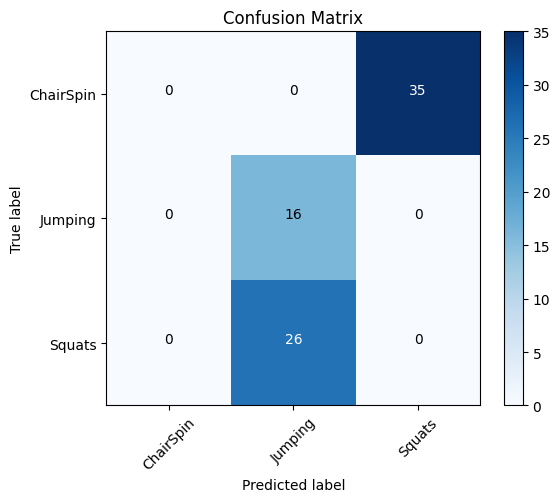

In [68]:
# =========================
# Detailed evaluation
# =========================
from sklearn.metrics import confusion_matrix, classification_report
labels_pred = model.predict(features_test).argmax(axis=1)
labels_true = labels_test

print("\nConfusion Matrix:")
print(confusion_matrix(labels_true, labels_pred))

print("\nClassification Report:")
print(classification_report(labels_true, labels_pred, target_names=label_map.keys()))

# Make nicer graphic with maptplotlib
import matplotlib.pyplot as plt

cm = confusion_matrix(labels_true, labels_pred)

class_names = list(label_map.keys())

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate each cell
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()
